In [1]:
import numpy as np
import fastplotlib as fpl
import matplotlib.pyplot as plt
import random
from tqdm.notebook import tqdm
import seaborn as sns
from qpsolvers import solve_qp
from itertools import product
from skophys.preprocessing import Vectorizer, UnVectorizer
import tifffile
import scipy

%matplotlib inline

fastplotlib version from git (0.4.0) and __version__ (0.5.0) don't match.
wgpu version from git (0.15.3) and __version__ (0.22.1) don't match.
rendercanvas version from git (2.0.0) and __version__ (2.0.1) don't match.


Image(value=b'\x89PNG\r\n\x1a\n\x00\x00\x00\rIHDR\x00\x00\x01,\x00\x00\x007\x08\x06\x00\x00\x00\xb6\x1bw\x99\x…

Valid,Device,Type,Backend,Driver
✅,AMD Radeon 780M (RADV GFX1103_R1),IntegratedGPU,Vulkan,Mesa 24.2.8
✅ (default),NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
✅,NVIDIA RTX A1000 6GB Laptop GPU,DiscreteGPU,Vulkan,550.142
❗ limited,"llvmpipe (LLVM 19.1.0, 256 bits)",CPU,Vulkan,Mesa 24.2.8 (LLVM 19.1.0)
❌,"AMD Radeon 780M (radeonsi, gfx1103_r1, LLVM 19.1.0, DRM 3.59, 6.12.4-200.fc41.x86_64)",Unknown,OpenGL,4.6 (Core Profile) Mesa 24.2.8


pygfx version from git (0.6.0) and __version__ (0.9.0) don't match.
Incompatible version of wgpu:
    Detected 0.15.3.post134+g6b77f99, need >=(0, 19, 0), <(0, 23, 0).
    To update, use e.g. `pip install -U wgpu`.
Incompatible version of pylinalg:
    Detected 0.6.3, need >=(0, 6, 7), <(0, 7, 0).
    To update, use e.g. `pip install -U pylinalg`.
/home/kushal/venvs/fpl/lib64/python3.12/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)


In [2]:
fpl.select_adapter(fpl.enumerate_adapters()[0])

# Top left corner of movie

In [3]:
movie = tifffile.imread("/home/kushal/caiman_data/example_movies/demoMovie.tif")[:, :40, :50]
movie.shape

(2000, 40, 50)

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
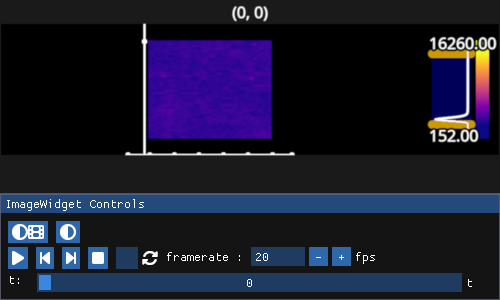

In [4]:
iw_movie = fpl.ImageWidget(movie)
iw_movie.show()

In [5]:
from skimage.transform import downscale_local_mean

# Subsample movie by a factor of 5

RFBOutputContext()

/home/kushal/repos/fastplotlib/fastplotlib/graphics/features/_base.py:18: UserWarning: casting float64 array to float32
  warn(f"casting {array.dtype} array to float32")


JupyterRenderCanvas(css_height='300.0px', css_width='500.0px')
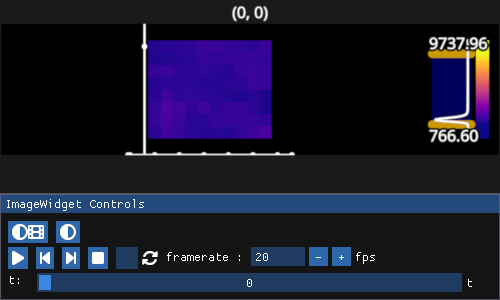

In [6]:
movie_sub = downscale_local_mean(movie, factors=(1, 5, 5))
fpl.ImageWidget(movie_sub).show()

In [32]:
def sim_matching_init(X_init, k, error_stop, eta=1e-1) -> tuple[np.ndarray, np.ndarray, int]:
    """
    Returns
    -------
        W, M, n_iter
    """
    cov = X_init.T @ X_init
    XTX = cov / np.linalg.norm(cov, ord="fro")
    
    T = XTX.shape[0]
    
    Y = (np.random.randn(k, T) / np.sqrt(T)).clip(0)

    error_log = np.zeros(3000)
    error_log[:] = np.nan

    for n_iter in tqdm(range(3_000)):
        Y_old = Y
        Y = Y + eta * Y @ (XTX - Y.T @ Y)
        
        zeroed = Y.sum(axis=1) == 0.0
        Y[zeroed] = (np.random.randn(zeroed.sum(), T) / np.sqrt(T)).clip(0)
        
        Y = Y.clip(0)
    
        er = np.divide(np.abs(Y - Y_old), np.abs(Y_old + 1e-2)).max() / eta
        error_log[n_iter] = er
    
        if er < error_stop:
            break
            
    W = Y @ X_init.T
    M = Y @ Y.T

    return W, M, n_iter, error_log

# Vectorize

In [8]:
unvec = UnVectorizer(movie_sub.shape[1:])
vectorizer = Vectorizer()
X = vectorizer.fit_transform(movie_sub)

In [9]:
X.shape

(80, 2000)

In [10]:
n_pixels = X.shape[0]

In [11]:
lag = 4
lag_step = 1

Hs = list()

for i in range(n_pixels):
    Hs.append(scipy.linalg.hankel(X[i, :lag * lag_step * 2], X[i, (lag * lag_step * 2) - 1:])[::lag_step])

H = np.zeros((lag * 2 * n_pixels, X.shape[1] - (lag * lag_step * 2) + 1))
for i, H_i in enumerate(Hs):
    H[i::n_pixels] = H_i

In [12]:
H.shape

(640, 1993)

In [13]:
mu0 = H[:lag * n_pixels].mean(axis=1)
mu1 = H[lag * n_pixels:].mean(axis=1)

In [14]:
H[:lag * n_pixels] -= mu0[:, None]
H[lag * n_pixels:] -= mu1[:, None]

In [15]:
def whiten_matrix(X, epsilon=1e-5):
    """
    Performs whitening on a given data matrix.

    Whitening, or decorrelation, is a data preprocessing technique that
    transforms a dataset such that its features become uncorrelated and
    have unit variance. The covariance matrix of the whitened data is the
    identity matrix.

    This implementation uses the Eigendecomposition method (PCA whitening).

    Parameters:
    - X (np.ndarray): The input data matrix, where each row is a sample
                      and each column is a feature. Shape (n_samples, n_features).
    - epsilon (float): A small constant added to the eigenvalues to ensure
                       numerical stability (avoids division by zero).

    Returns:
    - X_whitened (np.ndarray): The whitened data matrix with the same shape as X.
    """
    # 1. Center the data by subtracting the mean of each feature.
    # The mean is calculated along the columns (axis=0).
    X_mean = np.mean(X, axis=0)
    X_centered = X - X_mean

    # 2. Compute the covariance matrix of the centered data.
    # `rowvar=False` indicates that columns represent features, while rows are observations.
    cov_matrix = np.cov(X_centered, rowvar=False)

    # 3. Perform eigendecomposition of the covariance matrix.
    # `eigh` is used for symmetric matrices like the covariance matrix.
    # It returns eigenvalues in ascending order and corresponding eigenvectors.
    eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)

    # 4. Construct the whitening matrix.
    # This matrix is used to project the data into a new space where it is decorrelated.
    # It's formed by the eigenvectors and the inverse square root of the eigenvalues.
    # Epsilon is added to the eigenvalues to prevent division by zero for features
    # with zero variance.
    W = np.dot(eigenvectors, np.diag(1.0 / np.sqrt(eigenvalues + epsilon)))

    # 5. Transform the centered data to get the whitened data.
    # This is done by projecting the centered data onto the whitening matrix.
    X_whitened = np.dot(X_centered, W)

    return X_whitened, X_mean, W

In [16]:
past = H[:lag * n_pixels]
future = H[lag * n_pixels:]

In [17]:
Pw, _, _ = whiten_matrix(past)
Fw, _, _ = whiten_matrix(future)

In [18]:
Pw

array([[-1.26899522e-08,  4.43287718e-09, -3.38695827e-09, ...,
        -6.74941201e-01,  4.53738682e-01,  1.75341134e-01],
       [ 1.12231646e-08,  2.01544026e-09, -3.34330252e-09, ...,
        -4.41857112e-01,  4.13531252e-01,  3.38667398e-01],
       [-1.17433956e-08, -2.05818651e-09,  4.80213203e-10, ...,
        -1.90071870e-01,  2.23076276e-01,  2.40377181e-01],
       ...,
       [-4.25461621e-09,  1.27613475e-09, -7.00765668e-10, ...,
        -1.40531553e-01,  3.77626763e-01,  3.05600266e-01],
       [-3.85716703e-09,  2.61206878e-09, -7.28505256e-10, ...,
         1.57671490e-01, -5.50653656e-02,  4.46016784e-01],
       [-9.45510692e-09, -3.72165232e-09,  3.03430170e-10, ...,
         3.17718071e-01,  3.88675648e-02,  4.21959149e-01]])

# k: number of components

In [19]:
k = 2

# list of slices of lags, each slice is the indices in `W` that represent pixels for one lag time

In [20]:
lag_slices = [slice(n_pixels * i, (i + 1) * n_pixels) for i in range(lag)]
lag_slices

[slice(0, 80, None),
 slice(80, 160, None),
 slice(160, 240, None),
 slice(240, 320, None)]

In [21]:
H = np.vstack([Pw , Fw])

In [22]:
from itertools import product

# Offline sim matching and plot

Run this and every ~5 tries you may get something that resembles 2 of the neurons

  0%|          | 0/3000 [00:00<?, ?it/s]

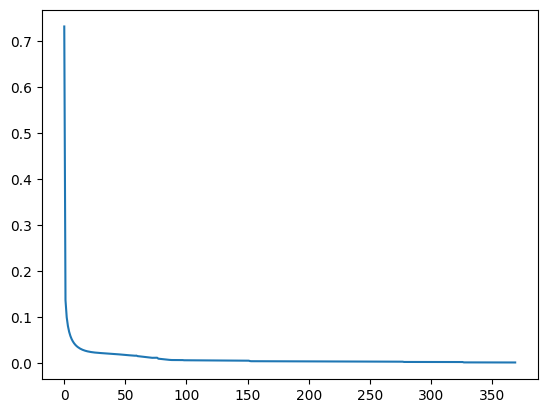

RFBOutputContext()

JupyterRenderCanvas(css_height='600.0px', css_width='1200.0px')
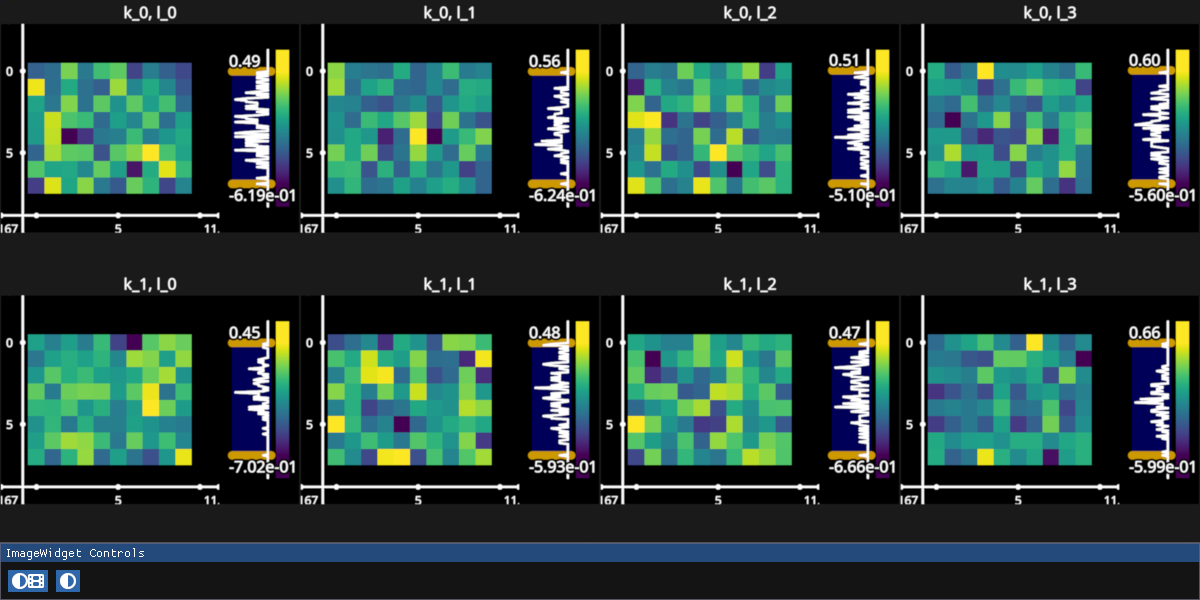

In [40]:
W, M, n_iter, errors = sim_matching_init(H, k, error_stop=1e-3, eta=8e-1)

plt.plot(errors)
plt.show()

# make images by reshaing each lag within `W`
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(W[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

iw_W = fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (1200, 600)},
)
iw_W.show()

# flip cmap if necessary

In [783]:
iw_W.cmap = "viridis_r"

In [784]:
def solve_yt(x_t, Wt, Mt, k):
    return solve_qp(
        (Mt + Mt.T) / 2,
        -Wt @ x_t,
        lb=np.zeros(k),
        solver="cvxopt"
    )

In [785]:
X_diag = np.diag(np.ones(H.shape[0]))

F = np.zeros((k, H.shape[0]))

for i in range(H.shape[0]):
    F[:, i] = solve_yt(X_diag[:, i], W, M, k)

F /= F.sum(axis=1)[:, None]

In [786]:
F.shape

(2, 640)

In [787]:
images, titles = list(), list(),
for k_i, l_i in product(range(k), range(lag)):
    images.append(unvec.transform(F[k_i, lag_slices[l_i]].T))
    titles.append(f"k_{k_i}, l_{l_i}")

RFBOutputContext()

JupyterRenderCanvas(css_height='600.0px', css_width='1200.0px')
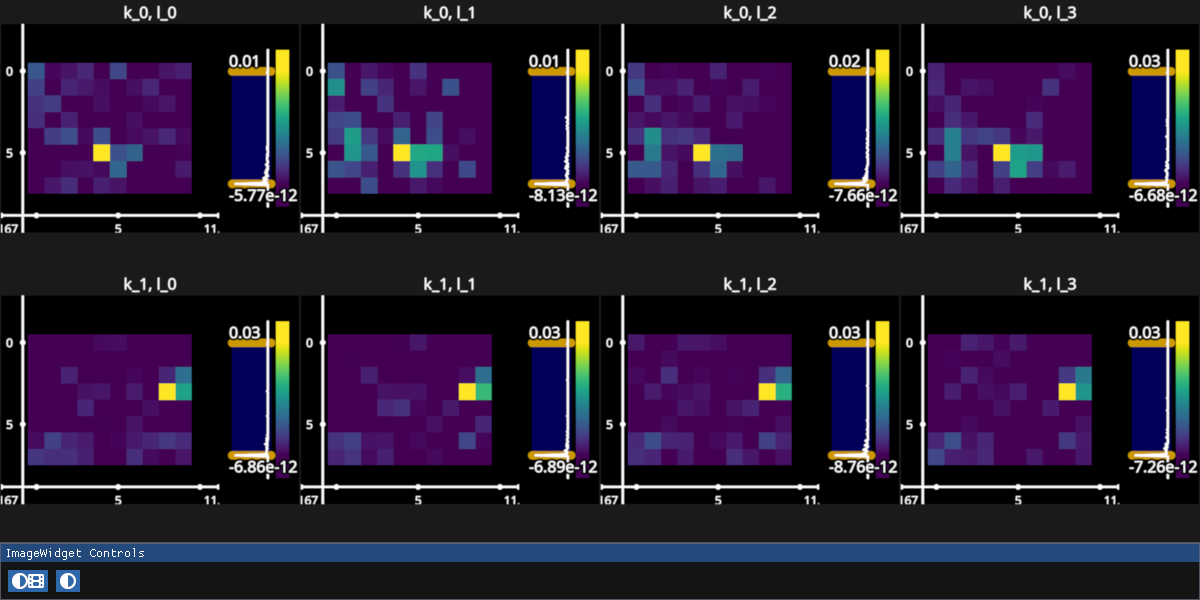

In [788]:
fpl.ImageWidget(
    images,
    cmap="viridis",
    names=titles,
    figure_shape=(k, lag),
    figure_kwargs={"size": (1200, 600)},
).show()